# <font color='gold'>Compare source vs. sample distributions</font>


In [1]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pandas import CategoricalDtype
from sampling_util.dictToExcel import df_dictToExcel

# Set style
plt.style.use('default')
sns.set_palette("husl")

sheetname_df_dict = dict()

source_file_dir = '../../data/1_processed/'
source_file_dict = ['1_He_2020_RMP_v2_with_sampling_criteria.csv', '2_Uwaterloo_course_reviews_with_sampling_criteria.csv', '3_UExeter_uni_reviews_with_sampling_criteria.csv']

sample_file = '../../data/2_sampled/combined_data_6.5k.csv'

output_file_dir = '../../data/2_sampled/sampling_output_stats'
output_filename = 'sample_distribution_comparison.xlsx'

#==========================================================

print(f"source_file_dir:    \033[36m{source_file_dir}\033[0m\n"
      f"sample_file:        \033[36m{sample_file}\033[0m\n\n"
      f"output_file:        \033[33m{os.path.join(output_file_dir, output_filename)}\033[0m"
      )


source_file_dir:    ../../data/1_processed/
sample_file:        ../../data/2_sampled/combined_data_6.5k.csv

output_file:        ../../data/2_sampled/sampling_output_stats/sample_distribution_comparison.xlsx


In [2]:
review_types = ['course', 'teacher', 'university']
titles = ['Course Reviews', 'Teacher Reviews', 'University Reviews', 'Overall (across review types)']
plot_order = ['course', 'teacher', 'university', 'overall']

# token_bins grouped lengh_bin with starting values greater than 301 into '(301, 861]', and replaced '.0' with ''
token_bins = [
    '[1, 21]', '(21, 41]', '(41, 61]', '(61, 81]', '(81, 101]',
    '(101, 121]', '(121, 141]', '(141, 161]', '(161, 181]', '(181, 201]',
    '(201, 221]', '(221, 241]', '(241, 261]', '(261, 281]', '(281, 301]',
    '(301, 861]'
]

rating_cat_values = ['High', 'Medium', 'Low']
rating_cat_orders = ['High', 'Medium', 'Low', '[NA]']

sentiment_ratingcat_map = {'Pos':'High', 'Conf/Neu':'Medium', 'Neg':'Low', '[NA]':'[NA]'}

#===============================================================

## <font color='cornflowerblue'>1. Get source and sample dataframes</font>

In [3]:
sourcedf_list = []

for file in source_file_dict:
    tempdf = pd.read_csv(os.path.join(source_file_dir,file))
    print(f"\noriginal cols:  {list(tempdf.columns.values)}")
    tempdf = tempdf[['type', 'id', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']]
    print(f"\nselected cols:  {list(tempdf.columns.values)}\n")
    display(tempdf.head(5))
    
    sourcedf_list.append(tempdf)


original cols:  ['Unnamed: 0', 'id', 'index', 'department', 'teacher_name', 'rating', 'review_text', 'source', 'type', 'token_list', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']

selected cols:  ['type', 'id', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']



,type,id,num_token,rating_bin,rating_cat,length_bin,sample_criteria
0,teacher review,1_90_2430_1,27,"(0.999, 2.5]",Neg,"(21.0, 41.0]","Neg_(21.0, 41.0]"
1,teacher review,1_236_180_2,75,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"
2,teacher review,1_182_1691_3,4,"(0.999, 2.5]",Neg,"(0.999, 21.0]","Neg_(0.999, 21.0]"
3,teacher review,1_40_401_4,73,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"
4,teacher review,1_37_1575_5,66,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"



original cols:  ['Unnamed: 0', 'id', 'entry_idx', 'course_code', 'course_id', 'num_ratings', 'useful', 'easy', 'liked', 'num_reviews', 'review_text', 'rating_category', 'rating', 'source', 'type', 'token_list', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']

selected cols:  ['type', 'id', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']



,type,id,num_token,rating_bin,rating_cat,length_bin,sample_criteria
0,course review,2_1_794,6,[1.0],Pos,"(0.999, 21.0]","Pos_(0.999, 21.0]"
1,course review,2_2_794,38,[0.0],Neg,"(21.0, 41.0]","Neg_(21.0, 41.0]"
2,course review,2_3_794,91,[0.0],Neg,"(81.0, 101.0]","Neg_(81.0, 101.0]"
3,course review,2_4_794,57,[1.0],Pos,"(41.0, 61.0]","Pos_(41.0, 61.0]"
4,course review,2_5_794,54,[1.0],Pos,"(41.0, 61.0]","Pos_(41.0, 61.0]"



original cols:  ['Unnamed: 0', 'id', 'index', 'student_id', 'date', 'review_text', 'rating', 'rating_facilities', 'rating_clubs', 'rating_careerService', 'rating_internet', 'source', 'type', 'token_list', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']

selected cols:  ['type', 'id', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']



,type,id,num_token,rating_bin,rating_cat,length_bin,sample_criteria
0,university review,3_1_469_129,7,"(4.0, 5.0]",Pos,"(0.999, 21.0]","Pos_(0.999, 21.0]"
1,university review,3_2_161_233,217,"(2.5, 4.0]",Conf/Neu,"(201.0, 221.0]","Conf/Neu_(201.0, 221.0]"
2,university review,3_3_160_142,43,"(2.5, 4.0]",Conf/Neu,"(41.0, 61.0]","Conf/Neu_(41.0, 61.0]"
3,university review,3_4_273_142,57,"(4.0, 5.0]",Pos,"(41.0, 61.0]","Pos_(41.0, 61.0]"
4,university review,3_5_272_119,29,"(4.0, 5.0]",Pos,"(21.0, 41.0]","Pos_(21.0, 41.0]"


In [4]:
sourcedf = pd.concat(sourcedf_list, ignore_index=True, sort=False)

if len(sourcedf) == sum(len(eachdf) for eachdf in sourcedf_list):
    print("\033[32mAll good\033[0m")
    sourcedf.rating_cat = sourcedf.rating_cat.map(sentiment_ratingcat_map)
    sourcedf.sample_criteria = sourcedf.sample_criteria.str.replace('Pos_', 'High_').str.replace('Conf/Neu_', 'Medium_').str.replace('Neg_', 'Low_')
else:
    print(len(sourcedf), [len(eachdf) for eachdf in sourcedf_list])
    raise ValueError("\033[32mTotal row numbers does not add up, check!!!\033[0m")

sourcedf

All good


,type,id,num_token,rating_bin,rating_cat,length_bin,sample_criteria
0,teacher review,1_90_2430_1,27,"(0.999, 2.5]",Low,"(21.0, 41.0]","Low_(21.0, 41.0]"
1,teacher review,1_236_180_2,75,"(0.999, 2.5]",Low,"(61.0, 81.0]","Low_(61.0, 81.0]"
2,teacher review,1_182_1691_3,4,"(0.999, 2.5]",Low,"(0.999, 21.0]","Low_(0.999, 21.0]"
3,teacher review,1_40_401_4,73,"(0.999, 2.5]",Low,"(61.0, 81.0]","Low_(61.0, 81.0]"
4,teacher review,1_37_1575_5,66,"(0.999, 2.5]",Low,"(61.0, 81.0]","Low_(61.0, 81.0]"
...,...,...,...,...,...,...,...
34507,university review,3_553_1_182,29,"(4.0, 5.0]",High,"(21.0, 41.0]","High_(21.0, 41.0]"
34508,university review,3_554_1_182,5,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]"
34509,university review,3_555_1_182,14,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]"
34510,university review,3_556_1_182,15,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]"


In [5]:
print(sourcedf.rating_cat.unique())

sourcedf.sample_criteria.str.split('_').str[0].unique()

['Low' 'Medium' 'High' '[NA]']


array(['Low', 'Medium', 'High', '[NA]'], dtype=object)

In [6]:
for each in sourcedf.type.unique():
    print(f"\033[36m{each}\033[0m")
    print(sorted(sourcedf.loc[sourcedf.type==each].num_token.unique()), '\n')

    sent_table = sourcedf.loc[sourcedf.type==each].rating_cat.value_counts().reset_index()

    sent_table['%'] = sent_table['count'] / sent_table['count'].sum()
    
    display(sent_table)
    

teacher review
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 90, 91, 92, 94, 96, 97, 101, 103, 108, 110, 124] 



,rating_cat,count,%
0,High,9970,0.520763
1,Low,4743,0.247741
2,Medium,4432,0.231496


course review
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219

,rating_cat,count,%
0,High,9778,0.660230
1,Low,4811,0.324848
2,[NA],221,0.014922


university review
[1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 49, 50, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 65, 66, 68, 69, 72, 73, 75, 76, 77, 81, 82, 83, 88, 91, 93, 100, 101, 102, 104, 106, 108, 114, 118, 123, 124, 128, 130, 134, 135, 137, 141, 146, 147, 181, 183, 187, 197, 215, 217] 



,rating_cat,count,%
0,High,406,0.728905
1,Medium,141,0.253142
2,Low,10,0.017953


In [7]:
sampledf = pd.read_csv(sample_file)

print(f"\noriginal cols:  {list(sampledf.columns.values)}")

sampledf = sampledf[['type', 'id', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']]
sampledf.rating_cat = sampledf.rating_cat.map(sentiment_ratingcat_map)
sampledf.sample_criteria = sampledf.sample_criteria.str.replace('Pos_', 'High_').str.replace('Conf/Neu_', 'Medium_').str.replace('Neg_', 'Low_')

print(f"\nselected cols:  {list(sampledf.columns.values)}\n")

print(len(sampledf))
sampledf


original cols:  ['type', 'source', 'id', 'rating', 'num_token', 'sample_criteria', 'review_text', 'rating_bin', 'rating_cat', 'length_bin']

selected cols:  ['type', 'id', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']

6500


,type,id,num_token,rating_bin,rating_cat,length_bin,sample_criteria
0,teacher review,1_45_2639_18911,74,"(4.0, 5.0]",High,"(61.0, 81.0]","High_(61.0, 81.0]"
1,teacher review,1_206_452_3440,56,"(0.999, 2.5]",Low,"(41.0, 61.0]","Low_(41.0, 61.0]"
2,teacher review,1_93_2121_1031,77,"(0.999, 2.5]",Low,"(61.0, 81.0]","Low_(61.0, 81.0]"
3,teacher review,1_89_50_4831,42,"(2.5, 4.0]",Medium,"(41.0, 61.0]","Medium_(41.0, 61.0]"
4,teacher review,1_88_396_5468,44,"(0.999, 2.5]",Low,"(41.0, 61.0]","Low_(41.0, 61.0]"
...,...,...,...,...,...,...,...
6495,university review,3_343_393_290,15,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]"
6496,university review,3_118_412_64,25,"(4.0, 5.0]",High,"(21.0, 41.0]","High_(21.0, 41.0]"
6497,university review,3_334_178_52,12,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]"
6498,university review,3_427_169_213,16,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]"


In [8]:
print(sampledf.rating_cat.unique())

sampledf.sample_criteria.str.split('_').str[0].unique()

['High' 'Low' 'Medium' '[NA]']


array(['High', 'Low', 'Medium', '[NA]'], dtype=object)

In [9]:
sourcedf.loc[:, 'file'] = 'source'
sampledf.loc[:,'file'] = 'sample'

concatdf = pd.concat([sourcedf, sampledf], ignore_index=True, sort=False)
concatdf.rating_cat = concatdf.rating_cat.astype(CategoricalDtype(categories=rating_cat_orders, ordered=True))

#------------------------------------------------------
df_to_add = concatdf
dfname = 'concatdf'

sheetname_df_dict[dfname] = df_to_add
print(f'\n\033[36m{dfname}\033[0m added to sheet.   len = \033[36m{len(df_to_add)}\033[0m\n')
df_to_add = None
#------------------------------------------------------

concatdf


concatdf added to sheet.   len = 41012



,type,id,num_token,rating_bin,rating_cat,length_bin,sample_criteria,file
0,teacher review,1_90_2430_1,27,"(0.999, 2.5]",Low,"(21.0, 41.0]","Low_(21.0, 41.0]",source
1,teacher review,1_236_180_2,75,"(0.999, 2.5]",Low,"(61.0, 81.0]","Low_(61.0, 81.0]",source
2,teacher review,1_182_1691_3,4,"(0.999, 2.5]",Low,"(0.999, 21.0]","Low_(0.999, 21.0]",source
3,teacher review,1_40_401_4,73,"(0.999, 2.5]",Low,"(61.0, 81.0]","Low_(61.0, 81.0]",source
4,teacher review,1_37_1575_5,66,"(0.999, 2.5]",Low,"(61.0, 81.0]","Low_(61.0, 81.0]",source
...,...,...,...,...,...,...,...,...
41007,university review,3_343_393_290,15,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]",sample
41008,university review,3_118_412_64,25,"(4.0, 5.0]",High,"(21.0, 41.0]","High_(21.0, 41.0]",sample
41009,university review,3_334_178_52,12,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]",sample
41010,university review,3_427_169_213,16,"(4.0, 5.0]",High,"(0.999, 21.0]","High_(0.999, 21.0]",sample


In [10]:
print(concatdf.rating_cat.unique())

concatdf.sample_criteria.str.split('_').str[0].unique()

['Low', 'Medium', 'High', '[NA]']
Categories (4, object): ['High' < 'Medium' < 'Low' < '[NA]']


array(['Low', 'Medium', 'High', '[NA]'], dtype=object)

In [11]:
table0 = concatdf[['file', 'length_bin', 'num_token', 'id']].copy().pivot_table(index=['length_bin', 'num_token'], columns=['file'], values='id', aggfunc='nunique').reset_index()

table0.loc[:,'start_length_val'] = table0.length_bin.str.split(',').str[0].str.replace('(', '').str.replace('[','').str.strip().astype(float)
table0 = table0.sort_values(by=['start_length_val'], ascending=[True])

table0.loc[len(table0)] = table0.sum(numeric_only=True, axis=0)

#------------------------------------------------------
df_to_add = table0
dfname = 'table0_numToken_and_bins'

sheetname_df_dict[dfname] = df_to_add
print(f'\n\033[36m{dfname}\033[0m added to sheet.   len = \033[36m{len(df_to_add)}\033[0m\n')
df_to_add = None
#------------------------------------------------------

table0



table0_numToken_and_bins added to sheet.   len = 332



file,length_bin,num_token,sample,source,start_length_val
0,"(0.999, 21.0]",1.0,34.0,161.0,0.999
19,"(0.999, 21.0]",20.0,91.0,442.0,0.999
18,"(0.999, 21.0]",19.0,72.0,389.0,0.999
17,"(0.999, 21.0]",18.0,108.0,450.0,0.999
16,"(0.999, 21.0]",17.0,81.0,398.0,0.999
...,...,...,...,...,...
287,"(581.0, 601.0]",588.0,NaN,1.0,581.000
288,"(581.0, 601.0]",590.0,NaN,1.0,581.000
309,"(621.0, 641.0]",635.0,NaN,1.0,621.000
330,"(841.0, 861.0]",856.0,NaN,1.0,841.000


In [12]:
#========================================================
# Re-bin high values to (301, 861]
def rebin_length(length_bin):
    if pd.isna(length_bin):
        return length_bin
    else:
        length_bin = length_bin.replace('.0','')
        if length_bin == '(0.999, 21]':
            return '[1, 21]'
        elif float(length_bin.split(',')[0][1:]) >= 301:  ## rebin entries above 301 tokens
            return '(301, 861]'
        return length_bin
#========================================================


table1 = concatdf.copy()

table1['length_bin'] = table1['length_bin'].apply(rebin_length)

# Calculate counts and percentages by type and file
table1_counts = table1.groupby(['length_bin', 'type', 'file', 'rating_cat'], observed=False)['id'].nunique().reset_index()
table1_counts.rename(columns={'id': 'count'}, inplace=True)

# Calculate total within each length_bin + type + file combination
table1_counts['total'] = table1_counts.groupby(['length_bin', 'type', 'file'])['count'].transform('sum')

# Calculate percentage
table1_counts['percentage'] = (table1_counts['count'] / table1_counts['total'] * 100).round(2)

# Create combined count (%) column
table1_counts['count_pct'] = table1_counts['count'].astype(str) + ' (' + table1_counts['percentage'].astype(str) + '%)'

# Calculate overall counts and percentages (across all review types)
overall_counts = table1.groupby(['length_bin', 'file', 'rating_cat'], observed=False)['id'].nunique().reset_index()
overall_counts.rename(columns={'id': 'count'}, inplace=True)

# Calculate total within each length_bin + file combination for overall
overall_counts['total'] = overall_counts.groupby(['length_bin', 'file'])['count'].transform('sum')

# Calculate overall percentage
overall_counts['percentage'] = (overall_counts['count'] / overall_counts['total'] * 100).round(2)

# Create combined count (%) column for overall
overall_counts['count_pct'] = overall_counts['count'].astype(str) + ' (' + overall_counts['percentage'].astype(str) + '%)'

# Pivot individual review types
table1_pivot = table1_counts.pivot_table(
    index=['length_bin', 'rating_cat'], 
    columns=['type', 'file'], 
    values='count_pct', 
    aggfunc='first',
    fill_value='0 (0%)',
    observed=False
).reset_index()

# Flatten column names for the main table
table1_pivot.columns = ['_'.join(col).strip('_') if col[0] not in ['length_bin', 'rating_cat'] else col[0] for col in table1_pivot.columns]

# Pivot overall data
overall_pivot = overall_counts.pivot_table(
    index=['length_bin', 'rating_cat'],
    columns='file',
    values='count_pct',
    aggfunc='first',
    fill_value='0 (0%)',
    observed=False
).reset_index()

# Rename overall columns
overall_pivot.columns = ['length_bin', 'rating_cat', 'sample overall', 'source overall']

# Merge the tables
table1 = pd.merge(table1_pivot, overall_pivot, on=['length_bin', 'rating_cat'], how='left')
table1.loc[:,'start_length_val'] = table1.length_bin.str.split(',').str[0].str.replace('(', '').str.replace('[','').str.strip().astype(float)

table1 = table1.sort_values(by=['start_length_val', 'rating_cat'], ascending=[True, True])

#------------------------------------------------------
df_to_add = table1
dfname = 'table1_length_bin_ratingCat'

sheetname_df_dict[dfname] = df_to_add
print(f'\n\033[36m{dfname}\033[0m added to sheet.   len = \033[36m{len(df_to_add)}\033[0m\n')
df_to_add = None
#------------------------------------------------------

table1


table1_length_bin_ratingCat added to sheet.   len = 64



,length_bin,rating_cat,course review_sample,course review_source,teacher review_sample,teacher review_source,university review_sample,university review_source,sample overall,source overall,start_length_val
60,"[1, 21]",High,680 (64.82%),3394 (65.09%),290 (60.42%),1849 (60.48%),230 (77.44%),256 (77.34%),1200 (65.72%),5499 (63.93%),1.0
61,"[1, 21]",Medium,0 (0.0%),0 (0.0%),87 (18.12%),551 (18.02%),64 (21.55%),71 (21.45%),151 (8.27%),622 (7.23%),1.0
62,"[1, 21]",Low,351 (33.46%),1730 (33.18%),103 (21.46%),657 (21.49%),3 (1.01%),4 (1.21%),457 (25.03%),2391 (27.8%),1.0
63,"[1, 21]",[NA],18 (1.72%),90 (1.73%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),18 (0.99%),90 (1.05%),1.0
24,"(21, 41]",High,541 (68.22%),2663 (68.19%),377 (56.95%),2406 (56.99%),79 (71.17%),88 (71.54%),997 (63.67%),5157 (62.51%),21.0
...,...,...,...,...,...,...,...,...,...,...,...
43,"(281, 301]",[NA],0 (0.0%),0 (0.0%),0 (nan%),0 (nan%),0 (nan%),0 (nan%),0 (0.0%),0 (0.0%),281.0
44,"(301, 861]",High,4 (30.77%),22 (40.0%),0 (nan%),0 (nan%),0 (nan%),0 (nan%),4 (30.77%),22 (40.0%),301.0
45,"(301, 861]",Medium,0 (0.0%),0 (0.0%),0 (nan%),0 (nan%),0 (nan%),0 (nan%),0 (0.0%),0 (0.0%),301.0
46,"(301, 861]",Low,9 (69.23%),33 (60.0%),0 (nan%),0 (nan%),0 (nan%),0 (nan%),9 (69.23%),33 (60.0%),301.0


In [13]:
def create_comprehensive_summary(concatdf, value_col='num_token', include_rating_cat=True, include_overall=True):
    """
    Create summary statistics and boxplot data from concatenated dataframe
    
    Parameters:
    concatdf: DataFrame with columns ['type', 'file', 'rating_cat', value_col]
    value_col: str, column name to apply `cal_stats` to (default 'num_token')
    include_rating_cat: bool, whether to break down by rating category (default True)
    include_overall: bool, whether to include overall statistics (default True)
    
    Returns:
    tuple: (summary_df, pivot_table)
    """
    #========================================
    # Calculate statistics of series
    def calc_stats(series):
        if len(series) == 0:
            return pd.Series({
                'N': 0, 'Min': np.nan, 'Q1': np.nan, 'Median': np.nan, 
                'Q3': np.nan, 'Max': np.nan, 'Mean': np.nan, 'Std_Dev': np.nan,
                'IQR': np.nan, 'Skewness': np.nan, 'Outliers_Count': 0
            })
        
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        outlier_threshold_high = q3 + 1.5 * iqr
        outlier_threshold_low = q1 - 1.5 * iqr
        outliers = ((series > outlier_threshold_high) | (series < outlier_threshold_low)).sum()
        
        return pd.Series({
            'N': len(series),
            'Min': series.min(),
            'Q1': q1,
            'Median': series.median(),
            'Q3': q3,
            'Max': series.max(),
            'Mean': series.mean(),
            'Std_Dev': series.std(ddof=1),
            'IQR': iqr,
            'Skewness': series.skew(),
            'Outliers_Count': outliers
        })
    #========================================
    
    review_type_order = ['Course', 'Teacher', 'University', 'Overall']
    
    # Clean and prepare data
    df = concatdf.copy()    
    df['Review_Type'] = df['type'].str.replace(' review', '').str.title()
    df['Data_Type'] = df['file'].str.title()
    
    #--------------------------------------------------------
    # 1. summary_stats
    #--------------------------------------------------------
    # Calculate statistics for individual review types
    group_cols = ['Review_Type', 'Data_Type', 'rating_cat'] if include_rating_cat else ['Review_Type', 'Data_Type']
    summary_stats = df.groupby(group_cols, observed=False)[value_col].apply(calc_stats).unstack()
    summary_stats = summary_stats.reset_index()
    
    # Add overall statistics if requested
    if include_overall:
        overall_group_cols = ['Data_Type', 'rating_cat'] if include_rating_cat else ['Data_Type']
        
        overall_stats = df.groupby(overall_group_cols, observed=False)[value_col].apply(calc_stats).unstack()
        overall_stats = overall_stats.reset_index()
        overall_stats['Review_Type'] = 'Overall'
        
        # Reorder columns to match
        cols = ['Review_Type'] + [col for col in overall_stats.columns if col != 'Review_Type']
        overall_stats = overall_stats[cols]
        
        summary_stats = pd.concat([summary_stats, overall_stats], ignore_index=True)
        
    # Sort and format summary statistics
    summary_stats['Review_Type'] = pd.Categorical(
        summary_stats['Review_Type'], 
        categories=review_type_order, 
        ordered=False
    )
    sort_order = ['Review_Type', 'rating_cat'] if include_rating_cat else ['Review_Type']
    summary_stats = summary_stats.sort_values(sort_order) 
    
    # Round numeric columns
    numeric_cols = ['N', 'Min', 'Max', 'Mean', 'Median', 'Std_Dev', 'Q1', 'Q3', 'IQR', 'Skewness', 'Outliers_Count']
    for col in numeric_cols:
        if col in summary_stats.columns:
            summary_stats[col] = summary_stats[col].round(2)
              
    #--------------------------------------------------------
    # 2. pivot_df
    #--------------------------------------------------------
    # Create pivot table for comparison
    key_stats = numeric_cols #['N', 'Median', 'Mean', 'Std_Dev', 'IQR']

    pivot_df = summary_stats.pivot_table(
        index=['Review_Type', 'rating_cat'] if include_rating_cat else 'Review_Type', 
        columns='Data_Type', 
        values=key_stats,
        aggfunc='first',
        observed=False
    )

    # Reorder columns
    stats_order = numeric_cols #['N','Mean', 'Max', 'Median', 'Mean', 'Std_Dev', 'IQR']
    data_type_order = ['Source', 'Sample']

    new_columns = []
    for stat in stats_order:
        for data_type in data_type_order:
            if (stat, data_type) in pivot_df.columns:
                new_columns.append((stat, data_type))

    pivot_df = pivot_df[new_columns]
    
    # Reset index to make index columns into regular columns
    pivot_df = pivot_df.reset_index()
    
    # Flatten multi-level column headers
    flattened_columns = []
    for col in pivot_df.columns:
        if isinstance(col, tuple) and len(col) == 2:
            # Multi-level column: combine stat and data_type
            flattened_columns.append(f"{col[0]} {col[1]}")
        else:
            # Single-level column (from reset_index)
            flattened_columns.append(col)
    
    pivot_df.columns = flattened_columns
    #--------------------------------------------------------
    
    return summary_stats, pivot_df

#================================================

In [14]:
# For token length only (Figure 1)
length_summary_stats_tokens, length_pivot_table = create_comprehensive_summary(
    concatdf, value_col='num_token', 
    include_rating_cat=False, 
    include_overall=True
)

#------------------------------------------------------
df_to_add = length_pivot_table
dfname = 'length_pivot_table'

sheetname_df_dict[dfname] = df_to_add
print(f'\n\033[36m{dfname}\033[0m added to sheet.   len = \033[36m{len(df_to_add)}\033[0m\n')
df_to_add = None
#------------------------------------------------------

length_pivot_table


length_pivot_table added to sheet.   len = 4



,Review_Type,N Source,N Sample,Min Source,Min Sample,Max Source,Max Sample,Mean Source,Mean Sample,Median Source,...,Q1 Source,Q1 Sample,Q3 Source,Q3 Sample,IQR Source,IQR Sample,Skewness Source,Skewness Sample,Outliers_Count Source,Outliers_Count Sample
0,Course,14810.0,3000.0,1.0,1.0,856.0,512.0,45.33,45.69,32.0,...,15.0,16.0,58.0,58.0,43.0,42.0,3.36,3.01,894.0,186.0
1,Teacher,19145.0,3000.0,1.0,1.0,124.0,94.0,47.77,47.69,51.0,...,30.0,30.0,67.0,67.0,37.0,37.0,-0.39,-0.40,1.0,0.0
2,University,557.0,500.0,1.0,1.0,217.0,217.0,28.35,28.42,18.0,...,11.0,11.0,32.0,32.0,21.0,21.0,2.96,3.04,46.0,40.0
3,Overall,34512.0,6500.0,1.0,1.0,856.0,512.0,46.41,45.29,43.0,...,22.0,19.0,66.0,64.0,44.0,45.0,3.39,3.03,763.0,170.0


In [15]:
# For token length × rating_cat (Figure 3)
boxplot_summary_stats, boxplot_pivot_table = create_comprehensive_summary(
    concatdf, value_col='num_token', 
    include_rating_cat=True, 
    include_overall=True
)

#------------------------------------------------------
df_to_add = boxplot_pivot_table
dfname = 'boxplot_pivot_table'

sheetname_df_dict[dfname] = df_to_add
print(f'\n\033[36m{dfname}\033[0m added to sheet.   len = \033[36m{len(df_to_add)}\033[0m\n')
df_to_add = None
#------------------------------------------------------

boxplot_pivot_table


boxplot_pivot_table added to sheet.   len = 13



,Review_Type,rating_cat,N Source,N Sample,Min Source,Min Sample,Max Source,Max Sample,Mean Source,Mean Sample,...,Q1 Source,Q1 Sample,Q3 Source,Q3 Sample,IQR Source,IQR Sample,Skewness Source,Skewness Sample,Outliers_Count Source,Outliers_Count Sample
0,Course,High,9778.0,1976.0,1.0,1.0,635.0,416.0,44.17,44.17,...,16.00,16.0,57.00,57.0,41.00,41.0,2.89,2.55,584.0,119.0
1,Course,Low,4811.0,979.0,1.0,1.0,856.0,512.0,47.95,49.04,...,15.00,15.0,61.00,61.5,46.00,46.5,3.70,3.23,306.0,64.0
2,Course,[NA],221.0,45.0,1.0,1.0,196.0,186.0,39.48,39.47,...,13.00,7.0,53.00,53.0,40.00,46.0,1.79,1.77,13.0,2.0
3,Teacher,High,9970.0,1561.0,1.0,1.0,124.0,94.0,45.31,45.20,...,27.00,27.0,65.00,66.0,38.00,39.0,-0.26,-0.26,1.0,0.0
4,Teacher,Medium,4432.0,696.0,1.0,1.0,108.0,88.0,50.43,50.33,...,35.00,35.0,69.00,69.0,34.00,34.0,-0.54,-0.57,0.0,0.0
5,Teacher,Low,4743.0,743.0,1.0,1.0,101.0,88.0,50.43,50.45,...,34.00,35.0,69.00,69.0,35.00,34.0,-0.56,-0.56,0.0,0.0
6,University,High,406.0,364.0,1.0,1.0,215.0,215.0,26.14,26.09,...,9.25,10.0,29.00,29.0,19.75,19.0,3.28,3.40,35.0,32.0
7,University,Medium,141.0,127.0,5.0,5.0,217.0,217.0,33.45,33.61,...,13.00,13.5,42.00,42.0,29.00,28.5,2.55,2.59,10.0,9.0
8,University,Low,10.0,9.0,15.0,15.0,118.0,118.0,46.40,49.22,...,19.50,19.0,57.25,60.0,37.75,41.0,1.25,1.09,1.0,0.0
9,Overall,High,20154.0,3901.0,1.0,1.0,635.0,416.0,44.37,42.90,...,20.00,18.0,63.00,61.0,43.00,43.0,2.82,2.50,490.0,112.0


### <font color='gold'>Write to Excel</font>

In [16]:
df_dictToExcel(excelfilename=os.path.join(output_file_dir,output_filename), sheetname_df_dict=sheetname_df_dict, freezeheader=True, headerfilter=True, locksheet=False, editable_range=None)
print(f"\033[32mFile writing done!  :)\033[30m") 

concatdf written to ../../data/2_sampled/sampling_output_stats/sample_distribution_comparison.xlsx.
table0_numToken_and_bins written to ../../data/2_sampled/sampling_output_stats/sample_distribution_comparison.xlsx.
table1_length_bin_ratingCat written to ../../data/2_sampled/sampling_output_stats/sample_distribution_comparison.xlsx.
length_pivot_table written to ../../data/2_sampled/sampling_output_stats/sample_distribution_comparison.xlsx.
boxplot_pivot_table written to ../../data/2_sampled/sampling_output_stats/sample_distribution_comparison.xlsx.


File writing done!  :)


## <font color='cornflowerblue'>2. Prepare data for graphing</font>

In [17]:

# Calculate sample sizes for subheadings
sample_sizes = {}
for plot_type in plot_order:
    if plot_type == 'overall':
        n_source = len(sourcedf)
        n_sample = len(sampledf)
    else:
        n_source = len(sourcedf[sourcedf['type'] == f'{plot_type} review'])
        n_sample = len(sampledf[sampledf['type'] == f'{plot_type} review'])
    
    sample_sizes[plot_type] = {'source': n_source, 'sample': n_sample}
    
sample_sizes

{'course': {'source': 14810, 'sample': 3000},
 'teacher': {'source': 19145, 'sample': 3000},
 'university': {'source': 557, 'sample': 500},
 'overall': {'source': 34512, 'sample': 6500}}

In [18]:

#===============================================================

def prepare_visualization_data(source_df, sample_df):
    """Convert raw data to visualization structures"""
    
    def clean_length_bins(df):
        """Clean and re-bin length_bin values"""
        df = df.copy()
        # Remove .0 from length_bin
        df['length_bin'] = df['length_bin'].str.replace('.0', '', regex=False)
        # Remove .0 from sample_criteria column
        df['sample_criteria'] = df['sample_criteria'].str.replace('.0', '', regex=False)
        
        df['length_bin'] = df['length_bin'].apply(rebin_length)
        return df
    
    # Clean both dataframes
    source_df = clean_length_bins(source_df)
    sample_df = clean_length_bins(sample_df)
    
    # Initialize data structures
    token_data = {}
    rating_cat_data = {}
    rating_cat_token_data = {}
    boxplot_data = {}
    
    for review_type in sorted(sourcedf.type.unique()):
        short_name = review_type.replace('review','').strip()
        
        #========= 1. Token length data ==============
        source_tokens = source_df[source_df['type']==review_type]['length_bin'].value_counts(normalize=True) * 100
        sample_tokens = sample_df[sample_df['type']==review_type]['length_bin'].value_counts(normalize=True) * 100
        
        token_data[short_name] = {
            'source': [source_tokens.get(bin, 0) for bin in token_bins],
            'sample': [sample_tokens.get(bin, 0) for bin in token_bins]
        }
        
        #========= 2. rating_cat data =================
        source_sent = source_df[source_df['type']==review_type]['rating_cat'].value_counts(normalize=True) * 100
        sample_sent = sample_df[sample_df['type']==review_type]['rating_cat'].value_counts(normalize=True) * 100
        
        rating_cat_data[short_name] = {
            'source': [source_sent.get(cat, 0) for cat in rating_cat_values],
            'sample': [sample_sent.get(cat, 0) for cat in rating_cat_values]
        }
        
        #========= 3. boxplot data using entry-level token length values and rating_cat ================
        boxplot_data[short_name] = {'source': {}, 'sample': {}}
        
        for data_type, df in [('source', source_df), ('sample', sample_df)]:
            df_filtered = df[df['type'] == review_type]
            
            for cat_value in rating_cat_values:
                # Extract actual token length values 
                token_values = df_filtered[df_filtered['rating_cat'] == cat_value]['num_token'].values
                boxplot_data[short_name][data_type][cat_value] = token_values
                
        #========= 4. rating_cat-token cross-tab using sample_criteria =================
        # For each token bin, calculate rating_cat percentages within that bin
        rating_cat_token_data[short_name] = {
            'source': {'High': [], 'Medium': [], 'Low': []},
            'sample': {'High': [], 'Medium': [], 'Low': []}
        }
                
        for token_bin in token_bins:
            bin_data_source = source_df[(source_df['type']==review_type) & (source_df['length_bin']==token_bin)]
            bin_data_sample = sample_df[(sample_df['type']==review_type) & (sample_df['length_bin']==token_bin)]
            
            # for source data
            if len(bin_data_source) > 0:
                source_sent_counts = bin_data_source['rating_cat'].value_counts(normalize=True) * 100
                rating_cat_token_data[short_name]['source']['High'].append(source_sent_counts.get('High', 0))
                rating_cat_token_data[short_name]['source']['Medium'].append(source_sent_counts.get('Medium', 0))
                rating_cat_token_data[short_name]['source']['Low'].append(source_sent_counts.get('Low', 0))
            else:
                rating_cat_token_data[short_name]['source']['High'].append(0)
                rating_cat_token_data[short_name]['source']['Medium'].append(0)
                rating_cat_token_data[short_name]['source']['Low'].append(0)
            
            # for sample data
            if len(bin_data_sample) > 0:
                sample_sent_counts = bin_data_sample['rating_cat'].value_counts(normalize=True) * 100
                rating_cat_token_data[short_name]['sample']['High'].append(sample_sent_counts.get('High', 0))
                rating_cat_token_data[short_name]['sample']['Medium'].append(sample_sent_counts.get('Medium', 0))
                rating_cat_token_data[short_name]['sample']['Low'].append(sample_sent_counts.get('Low', 0))
            else:
                rating_cat_token_data[short_name]['sample']['High'].append(0)
                rating_cat_token_data[short_name]['sample']['Medium'].append(0)
                rating_cat_token_data[short_name]['sample']['Low'].append(0)
                
    #========= 5. Add overall distributions to all data structures =================
    
    # 5-1. Overall token data
    source_tokens_overall = source_df['length_bin'].value_counts(normalize=True) * 100
    sample_tokens_overall = sample_df['length_bin'].value_counts(normalize=True) * 100
    token_data['overall'] = {
        'source': [source_tokens_overall.get(bin, 0) for bin in token_bins],
        'sample': [sample_tokens_overall.get(bin, 0) for bin in token_bins]
    }
    
    # 5-2. Overall rating_cat data
    source_sent_overall = source_df['rating_cat'].value_counts(normalize=True) * 100
    sample_sent_overall = sample_df['rating_cat'].value_counts(normalize=True) * 100
    rating_cat_data['overall'] = {
        'source': [source_sent_overall.get(cat, 0) for cat in rating_cat_values],
        'sample': [sample_sent_overall.get(cat, 0) for cat in rating_cat_values]
    }
    
    # 5-3. Overall boxplot data
    boxplot_data['overall'] = {'source': {}, 'sample': {}}
    for data_type, df in [('source', source_df), ('sample', sample_df)]:
        for cat_value in rating_cat_values:
            token_values = df[df['rating_cat'] == cat_value]['num_token'].values
            boxplot_data['overall'][data_type][cat_value] = token_values
    
    # 5-4. Overall rating_cat-token data
    rating_cat_token_data['overall'] = {
        'source': {'High': [], 'Medium': [], 'Low': []},
        'sample': {'High': [], 'Medium': [], 'Low': []}
    }
    
    for token_bin in token_bins:
        # Source data
        bin_data_source = source_df[source_df['length_bin'] == token_bin]
        if len(bin_data_source) > 0:
            source_sent_counts = bin_data_source['rating_cat'].value_counts(normalize=True) * 100
            rating_cat_token_data['overall']['source']['High'].append(source_sent_counts.get('High', 0))
            rating_cat_token_data['overall']['source']['Medium'].append(source_sent_counts.get('Medium', 0))
            rating_cat_token_data['overall']['source']['Low'].append(source_sent_counts.get('Low', 0))
        else:
            rating_cat_token_data['overall']['source']['High'].append(0)
            rating_cat_token_data['overall']['source']['Medium'].append(0)
            rating_cat_token_data['overall']['source']['Low'].append(0)
        
        # Sample data  
        bin_data_sample = sample_df[sample_df['length_bin'] == token_bin]
        if len(bin_data_sample) > 0:
            sample_sent_counts = bin_data_sample['rating_cat'].value_counts(normalize=True) * 100
            rating_cat_token_data['overall']['sample']['High'].append(sample_sent_counts.get('High', 0))
            rating_cat_token_data['overall']['sample']['Medium'].append(sample_sent_counts.get('Medium', 0))
            rating_cat_token_data['overall']['sample']['Low'].append(sample_sent_counts.get('Low', 0))
        else:
            rating_cat_token_data['overall']['sample']['High'].append(0)
            rating_cat_token_data['overall']['sample']['Medium'].append(0)
            rating_cat_token_data['overall']['sample']['Low'].append(0)
    
    return token_data, rating_cat_data, rating_cat_token_data, boxplot_data

#=====================================================================================================-----=====

token_data, rating_cat_data, rating_cat_token_data, boxplot_data = prepare_visualization_data(sourcedf, sampledf)

rating_cat_token_data

{'course': {'source': {'High': [65.0939777522056,
    68.19462227912932,
    67.3289183222958,
    67.44536548605879,
    62.655601659751035,
    64.8068669527897,
    63.138686131386855,
    62.5,
    61.111111111111114,
    69.66292134831461,
    62.295081967213115,
    39.58333333333333,
    54.285714285714285,
    55.00000000000001,
    55.00000000000001,
    40.0],
   'Medium': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
   'Low': [33.179900268507865,
    30.422535211267604,
    30.86092715231788,
    31.876412961567446,
    36.09958506224066,
    33.69098712446352,
    36.13138686131387,
    35.0,
    37.96296296296296,
    26.96629213483146,
    37.704918032786885,
    60.416666666666664,
    45.714285714285715,
    45.0,
    45.0,
    60.0]},
  'sample': {'High': [64.8236415633937,
    68.2219419924338,
    67.3913043478261,
    67.4074074074074,
    62.585034013605444,
    64.21052631578948,
    63.63636363636363,
    62.5,
    61.904761904761905,
    68.42105263157895,


In [19]:
boxplot_data

{'course': {'source': {'High': array([  6,  57,  54, ..., 110, 127,  38]),
   'Medium': array([], dtype=int64),
   'Low': array([ 38,  91, 190, ...,  94,  26,  76])},
  'sample': {'High': array([ 13,  26,  58, ..., 153,   5,  45]),
   'Medium': array([], dtype=int64),
   'Low': array([  3,  12,  14,  16,  14,  57,  41,  21,  26,  66,   5,   2,  44,
            7,  55,  22,  10,  16,  54,  71,  18,  38,   2,  57,   9,  51,
            4,  53,  21,  10,  71,  29, 103,  72,  30,  26,  39,  36,  12,
           45,  67,  26,  16,   6,  11,   5,  18,  25,  28,  48,   2,   5,
           47,  21,  28, 231,  10,  44,   7,  47,   1,  41,  79,  55,  36,
           31,   5,  43,  16,  14,  45,   9,   1,   8,  72,  67,   2,  29,
           26,  61,  39,  30,  40,  56,  52,   5,  40,  12,  42,  19,  72,
           25, 145,  14,  77,  26,  79,  20,  20,  59,   2,  14,  26, 117,
          162,   6,  96, 168,  59,  58,  51,  28,  33,  29,  19,  58, 163,
           18, 226,  19,  60,  93,   8,  26,  27,

In [20]:
pd.options.mode.chained_assignment = None # surpress SettingWithCopyWarning

for each in concatdf.file.unique():
    xx = concatdf.copy()
    xx = xx.loc[(xx.file==each)]
    
    display(xx.groupby(by=['file', 'type']).id.nunique().reset_index())
    
    print("\n\033[35mCount of entries with num_token > 301  (length_bin start value >= 301):\033[0m")
    
    yy = xx.loc[xx.num_token > 301]
    yy.loc[:,'min_tok'] = yy.num_token.min()
    yy = yy[['type', 'min_tok', 'num_token', 'length_bin','id','file']].sort_values(by='num_token')
    display(yy.groupby(by=['file', 'type', 'min_tok']).id.nunique().reset_index())
    print("\n")
    
pd.options.mode.chained_assignment = 'warn' # resume SettingWithCopyWarning

,file,type,id
0,source,course review,14810
1,source,teacher review,19145
2,source,university review,557



Count of entries with num_token > 301  (length_bin start value >= 301):


,file,type,min_tok,id
0,source,course review,303,55


,file,type,id
0,sample,course review,3000
1,sample,teacher review,3000
2,sample,university review,500



Count of entries with num_token > 301  (length_bin start value >= 301):


,file,type,min_tok,id
0,sample,course review,306,13


## <font color='cornflowerblue'>3. Graphing</font>

Fig 1 saved to ../../data/2_sampled/sampling_output_stats/Fig1 - token length distribution bargraph.png



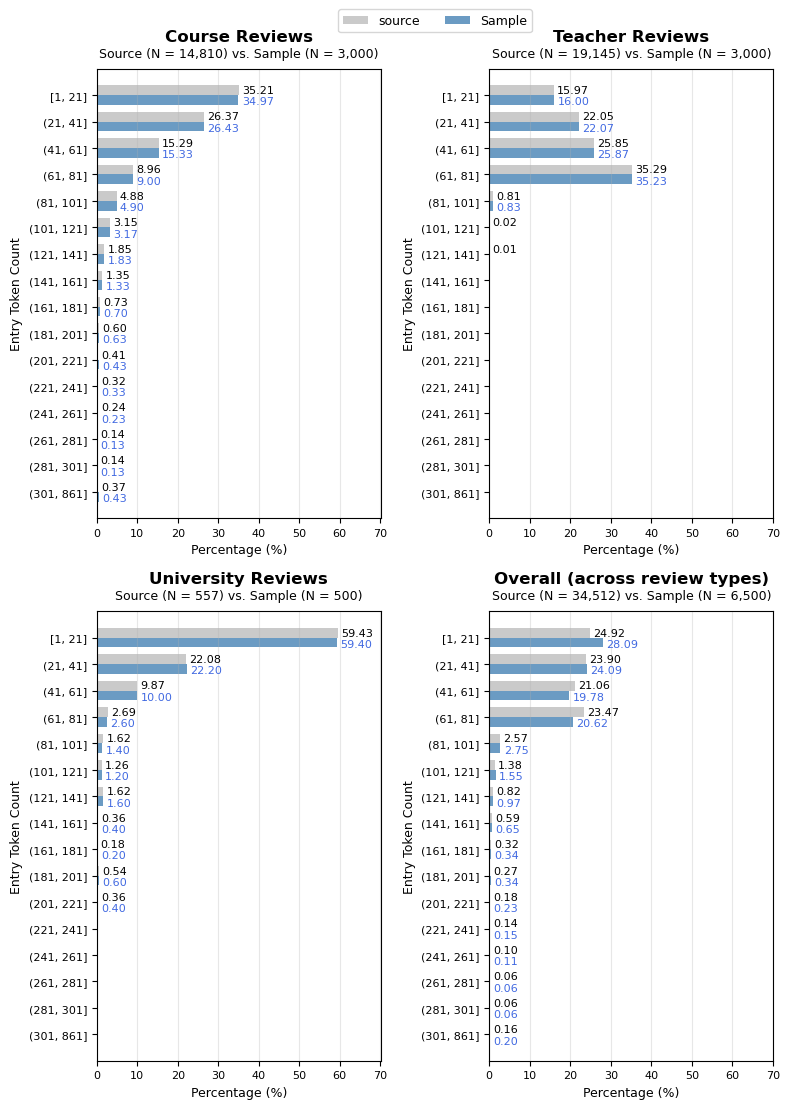

In [21]:
# FIGURE 1: Token Length Distribution (Horizontal bars)
fig1_path = os.path.join(output_file_dir, 'Fig1 - token length distribution bargraph.png')
fig1, axes = plt.subplots(2, 2, figsize=(8, 11))

# fig1.suptitle('Figure 1: Entry Token Length Distribution - Source vs Sample', fontsize=16, fontweight='bold', y=0.98)

# Calculate global x-range for consistent scaling
global_max = 0
for plot_type in plot_order:
    if plot_type == 'overall':
        # # if using mean of review types:
        # overall_orig = np.mean([token_data[rt]['source'] for rt in review_types], axis=0)
        # overall_samp = np.mean([token_data[rt]['sample'] for rt in review_types], axis=0)
        # global_max = max(global_max, max(overall_orig), max(overall_samp))
        # if using true overall across review types:
        global_max = max(global_max, max(token_data['overall']['source']), max(token_data['overall']['sample']))
    else:
        global_max = max(global_max, max(token_data[plot_type]['source']), max(token_data[plot_type]['sample']))

buffer = max(3, global_max * 0.18)
global_xlim = global_max + buffer

for i, plot_type in enumerate(plot_order):
    row, col = i // 2, i % 2
    ax = axes[row, col]
    
    y = np.arange(len(token_bins)) * 1.5
    height = 0.55
    gap = 0  # Gap between bar pairs
    
    if plot_type == 'overall':
        # # Overall plot - if use mean of review types
        # overall_orig = np.mean([token_data[rt]['source'] for rt in review_types], axis=0)
        # overall_samp = np.mean([token_data[rt]['sample'] for rt in review_types], axis=0)
        
        # Overall plot - if use overall across review types
        overall_orig = np.array(token_data['overall']['source'])
        overall_samp = np.array(token_data['overall']['sample'])
        
        bars1 = ax.barh(y - height/2 - gap/2, overall_orig, height, label='source', alpha=0.8, color='#BDBDBD') #, hatch='/////')
        bars2 = ax.barh(y + height/2 + gap/2, overall_samp, height, label='Sample', alpha=0.8, color='steelblue')
        
        # Add data labels
        # for j, (bar1, bar2) in enumerate(zip(bars1, bars2)):
        #     ax.text(bar1.get_width() + 0.3, bar1.get_y() + bar1.get_height()/2, f'{overall_orig[j]:.2f}', va='center', color='black', fontsize=8)
        #     ax.text(bar2.get_width() + 0.3, bar2.get_y() + bar2.get_height()/2, f'{overall_samp[j]:.2f}', va='center', color='royalblue', fontsize=8)
        
        # Add data labels, skip 0 values
        for j, (bar1, bar2) in enumerate(zip(bars1, bars2)):
            if overall_orig[j] > 0:
                ax.text(bar1.get_width() + 0.8, bar1.get_y() + bar1.get_height()/2, f'{overall_orig[j]:.2f}', va='center', color='black', fontsize=8)
            if overall_samp[j] > 0:
                ax.text(bar2.get_width() + 0.8, bar2.get_y() + bar2.get_height()/1.5, f'{overall_samp[j]:.2f}', va='center', color='royalblue', fontsize=8)
    else:
        # Individual review type plots
        bars1 = ax.barh(y - height/2 - gap/2, token_data[plot_type]['source'], height, label='source', alpha=0.8, color='#BDBDBD') #, hatch='/////')
        bars2 = ax.barh(y + height/2 + gap/2, token_data[plot_type]['sample'], height, label='Sample', alpha=0.8, color='steelblue')
        
        # Add data labels
        # for j, (bar1, bar2) in enumerate(zip(bars1, bars2)):
        #     ax.text(bar1.get_width() + 0.3, bar1.get_y() + bar1.get_height()/2, f'{token_data[plot_type]["source"][j]:.2f}', va='center', color='black', fontsize=8)
        #     ax.text(bar2.get_width() + 0.3, bar2.get_y() + bar2.get_height()/2, f'{token_data[plot_type]["sample"][j]:.2f}', va='center', color='royalblue', fontsize=8)
        
        # Add data labels, skip 0 values
        for j, (bar1, bar2) in enumerate(zip(bars1, bars2)):
            if token_data[plot_type]["source"][j] > 0:
                ax.text(bar1.get_width() + 0.8, bar1.get_y() + bar1.get_height()/2, f'{token_data[plot_type]["source"][j]:.2f}', va='center', color='black', fontsize=8)
            if token_data[plot_type]["sample"][j] > 0:
                ax.text(bar2.get_width() + 0.8, bar2.get_y() + bar2.get_height()/1.5, f'{token_data[plot_type]["sample"][j]:.2f}', va='center', color='royalblue', fontsize=8)
            
    # Ensure data label stays within subplot
    max_val = max(max(overall_orig if plot_type == 'overall' else token_data[plot_type]['source']), 
                  max(overall_samp if plot_type == 'overall' else token_data[plot_type]['sample']))
    
    # ax.set_xlim(0, max_val + 4)  # Add buffer for labels
    
    # Calculate buffer based on longest value
    # max_label_len = len(f'{max_val:.2f}')
    # buffer = max(3, max_label_len * 1)
    # ax.set_xlim(0, max_val + buffer)
    
    ax.set_title(titles[i], fontweight='bold', pad=20) # pad = 8 if without subheading
    
    # Add subheading with sample sizes
    subtitle = f"Source (N = {sample_sizes[plot_type]['source']:,}) vs. Sample (N = {sample_sizes[plot_type]['sample']:,})"
    ax.text(0.5, 1.02, subtitle, transform=ax.transAxes, ha='center', va='bottom', fontsize=9)
    
    ax.tick_params(axis='both', labelsize=8)  # Reduce tick label font size
    
    ax.set_xlim(0, global_xlim)
    ax.set_xlabel('Percentage (%)', fontsize=9)
    
    if i in range(len(plot_order)):
        ax.set_ylabel('Entry Token Count', fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels(token_bins)
    ax.invert_yaxis()
    
    ax.grid(True, alpha=0.3, axis='x')
    
    # Reduce space at top and bottom of y-axis
    ax.margins(y=0.04)  # Default is usually 0.05, reduce to 0.02
    
    
# Add shared legend centered horizontally
handles, labels = axes[0,0].get_legend_handles_labels()
fig1.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.55, 1.01), fontsize=9)
plt.subplots_adjust(top=0.93)
    
plt.tight_layout()
plt.savefig(fig1_path, bbox_inches='tight', dpi=1080)
print(f"\033[33mFig 1 saved to {fig1_path}\033[0m\n")
plt.show()

Fig 2 saved to ../../data/2_sampled/sampling_output_stats/Fig2 - rating category column graph.png



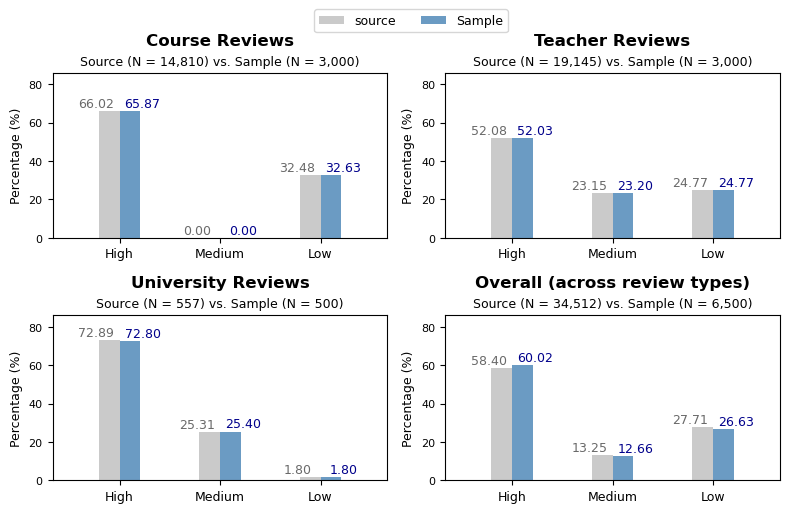

In [22]:
# FIGURE 2: rating_cat Distribution
fig2_path = os.path.join(output_file_dir, 'Fig2 - rating category column graph.png')

fig2, axes = plt.subplots(2, 2, figsize=(8, 5))

# Calculate global y-range for consistent scaling
global_max = 0
for plot_type in plot_order:
    if plot_type == 'overall':
        ## if use mean of review types
        # overall_orig = np.mean([rating_cat_data[rt]['source'] for rt in review_types], axis=0)
        # overall_samp = np.mean([rating_cat_data[rt]['sample'] for rt in review_types], axis=0)
        # global_max = max(global_max, max(overall_orig), max(overall_samp))
    
        ## if use overall across review types
        global_max = max(global_max, max(rating_cat_data['overall']['source']), max(rating_cat_data['overall']['sample']))
    else:
        global_max = max(global_max, max(rating_cat_data[plot_type]['source']), max(rating_cat_data[plot_type]['sample']))

# Dynamic buffer based on data range
buffer = max(3, global_max * 0.18)  # At least 3, or 15% of max value
global_ylim = global_max + buffer


for i, plot_type in enumerate(plot_order):
    row, col = i // 2, i % 2
    ax = axes[row, col]
    
    x = np.arange(len(rating_cat_values)) * 1.2 + 0.6  # Spread out with margins
    width = 0.25
    
    if plot_type == 'overall':
        # # Overall rating_cat plot - if use mean of review types
        # overall_orig = np.mean([rating_cat_data[rt]['source'] for rt in review_types], axis=0)
        # overall_samp = np.mean([rating_cat_data[rt]['sample'] for rt in review_types], axis=0)
        
        # Overall rating_cat plot - if use overall across review types
        overall_orig = np.array(rating_cat_data['overall']['source'])
        overall_samp = np.array(rating_cat_data['overall']['sample'])
        
        bars1 = ax.bar(x - width/2, overall_orig, width, label='source', alpha=0.8, color='#BDBDBD') #, hatch='/////')
        bars2 = ax.bar(x + width/2, overall_samp, width, label='Sample', alpha=0.8, color='steelblue')
        
        # Add data labels
        for j, (bar1, bar2) in enumerate(zip(bars1, bars2)):
            ax.text(bar1.get_x() + bar1.get_width()/2 - 0.15, bar1.get_height() + 2, f'{overall_orig[j]:.2f}', ha='center', color='dimgray', fontsize=9)
            ax.text(bar2.get_x() + bar2.get_width()/2 + 0.15, bar2.get_height() + 2, f'{overall_samp[j]:.2f}', ha='center', color='darkblue', fontsize=9)
        
        # Set ylim to accommodate labels
        max_val = max(max(overall_orig), max(overall_samp))
        # ax.set_ylim(0, max_val + 5)
        ax.set_ylim(0, global_ylim)
    else:
        # Individual review type plots
        bars1 = ax.bar(x - width/2, rating_cat_data[plot_type]['source'], width, label='source', alpha=0.8, color='#BDBDBD') #, hatch='/////')
        bars2 = ax.bar(x + width/2, rating_cat_data[plot_type]['sample'], width, label='Sample', alpha=0.8, color='steelblue')
        
        # Add data labels
        for j, (bar1, bar2) in enumerate(zip(bars1, bars2)):
            ax.text(bar1.get_x() + bar1.get_width()/2 - 0.15, bar1.get_height() + 2, f'{rating_cat_data[plot_type]["source"][j]:.2f}', ha='center', color='dimgray', fontsize=9)
            ax.text(bar2.get_x() + bar2.get_width()/2 + 0.15, bar2.get_height() + 2, f'{rating_cat_data[plot_type]["sample"][j]:.2f}', ha='center', color='darkblue', fontsize=9)
        
        # Set ylim to accommodate labels
        max_val = max(max(rating_cat_data[plot_type]['source']), max(rating_cat_data[plot_type]['sample']))
        # ax.set_ylim(0, max_val + 5)
        ax.set_ylim(0, global_ylim)
    
    ax.set_title(titles[i], fontweight='bold', pad=20) # pad = 8 if without subheading
    
    # Add subheading with sample sizes
    subtitle = f"Source (N = {sample_sizes[plot_type]['source']:,}) vs. Sample (N = {sample_sizes[plot_type]['sample']:,})"
    ax.text(0.5, 1.03, subtitle, transform=ax.transAxes, ha='center', va='bottom', fontsize=9)
    
    
    ax.tick_params(axis='both', labelsize=8)  # Reduce tick label font size
    
    ax.set_ylabel('Percentage (%)', fontsize=9)
    # for i in range(len(rating_cat_values)):
    #     ax.set_xlabel('Rating Category', fontsize=9, labelpad=6)
    ax.set_xticks(x)
    ax.set_xticklabels(rating_cat_values, fontsize=9)
    ax.set_xlim(-0.2, max(x) + 0.8)  # Add margins on left and right
    
# Add shared legend centered horizontally
handles, labels = axes[0,0].get_legend_handles_labels()
fig2.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.52, 1.03), fontsize=9)
plt.subplots_adjust(top=0.93, hspace=0.6)

plt.tight_layout()
plt.savefig(fig2_path, bbox_inches='tight', dpi=1080)
print(f"\033[33mFig 2 saved to {fig2_path}\033[0m\n")

plt.show()

Fig 3 saved to ../../data/2_sampled/sampling_output_stats/Fig3 - length by rating_cat distribution boxplot (ylim=600).png



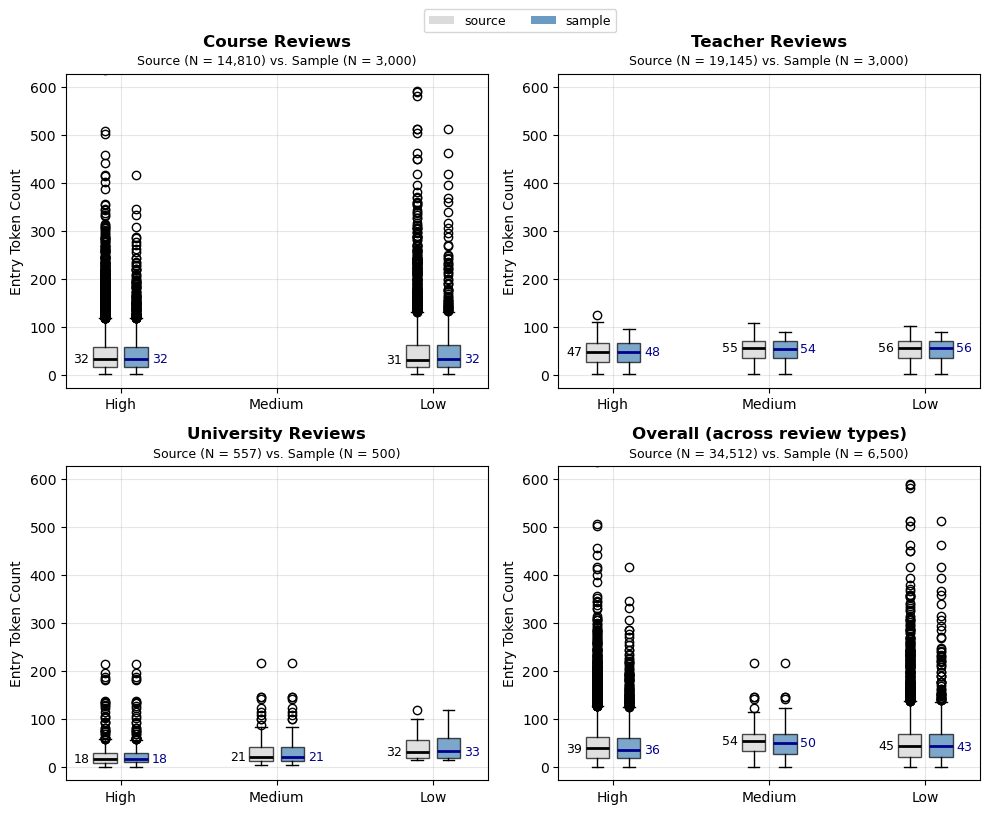

In [23]:
# FIGURE 3: Token Length × rating_cat Boxplots
fig3_path = os.path.join(output_file_dir, 'Fig3 - length by rating_cat distribution boxplot (ylim=600).png')

fig3, axes = plt.subplots(2, 2, figsize=(10, 8))
# fig3.suptitle('Figure 3: Token Length Distribution by rating_cat Category', fontsize=16, fontweight='bold', y=0.98)


# Calculate overall y-range for consistent scaling
all_values = []
for plot_type in plot_order:
    if plot_type == 'overall':
        for cat_value in rating_cat_values:
            
            # # if using mean of review types
            # for rt in review_types:
            #     all_values.extend(boxplot_data[rt]['source'][cat_value])
            #     all_values.extend(boxplot_data[rt]['sample'][cat_value])
        
            # if using overall across review types
            all_values.extend(boxplot_data['overall']['source'][cat_value])
            all_values.extend(boxplot_data['overall']['sample'][cat_value])
    else:
        for cat_value in rating_cat_values:
            all_values.extend(boxplot_data[plot_type]['source'][cat_value])
            all_values.extend(boxplot_data[plot_type]['sample'][cat_value])

# y_min, y_max = min(all_values), max(all_values)

## Version 2 - more focused y-range, mention outliers in figure caption:
y_min, y_max = min(all_values), 570
y_range = y_max - y_min
ylim_min = y_min - 0.05 * y_range
ylim_max = y_max + 0.1 * y_range


for i, plot_type in enumerate(plot_order):
    row, col = i // 2, i % 2
    ax = axes[row, col]
    
    if plot_type == 'overall':
        # Overall boxplot (combine all review types)
        all_data_orig = []
        all_data_samp = []
        
        for cat_value in rating_cat_values:
            # # Combine data from all review types
            # combined_orig = np.concatenate([boxplot_data[rt]['source'][cat_value] for rt in review_types])
            # combined_samp = np.concatenate([boxplot_data[rt]['sample'][cat_value] for rt in review_types])
            
            # if using overall across review types
            combined_orig = boxplot_data['overall']['source'][cat_value]
            combined_samp = boxplot_data['overall']['sample'][cat_value]
    
            all_data_orig.append(combined_orig)
            all_data_samp.append(combined_samp)
        
        # Create positions for side-by-side boxplots
        positions_orig = [1, 3, 5]
        positions_samp = [1.4, 3.4, 5.4]
        
        # Plot boxplots
        bp1 = ax.boxplot(all_data_orig, positions=positions_orig, widths=0.3, 
                        patch_artist=True, boxprops=dict(facecolor='lightgrey', alpha=0.7),
                        medianprops=dict(color='black', linewidth=2))
        bp2 = ax.boxplot(all_data_samp, positions=positions_samp, widths=0.3, 
                        patch_artist=True, boxprops=dict(facecolor='steelblue', alpha=0.7),
                        medianprops=dict(color='darkblue', linewidth=2))
        
        # Add median values as text
        for j, (data_orig, data_samp) in enumerate(zip(all_data_orig, all_data_samp)):
            if len(data_orig) > 0:
                median_orig = np.median(data_orig)
                ax.text(positions_orig[j] - 0.3, median_orig, f'{median_orig:.0f}',
                        ha='center', va='center', color='black', fontsize=9) #, fontweight='bold')
            if len(data_samp) > 0:
                median_samp = np.median(data_samp)
                ax.text(positions_samp[j] + 0.3, median_samp, f'{median_samp:.0f}',
                        ha='center', va='center', color='darkblue', fontsize=9) #, fontweight='bold')
        
        ax.set_xticks([1.2, 3.2, 5.2])
        ax.set_xticklabels(rating_cat_values, fontsize=10)
        
    else:
        # Individual review type boxplots
        data_orig = [boxplot_data[plot_type]['source'][s] for s in rating_cat_values]
        data_samp = [boxplot_data[plot_type]['sample'][s] for s in rating_cat_values]
        
        positions_orig = [1, 3, 5]
        positions_samp = [1.4, 3.4, 5.4]
        
        bp1 = ax.boxplot(data_orig, positions=positions_orig, widths=0.3, 
                        patch_artist=True, boxprops=dict(facecolor='lightgrey', alpha=0.7),
                        medianprops=dict(color='black', linewidth=2))
        bp2 = ax.boxplot(data_samp, positions=positions_samp, widths=0.3, 
                        patch_artist=True, boxprops=dict(facecolor='steelblue', alpha=0.7),
                        medianprops=dict(color='darkblue', linewidth=2))
        
        # Add median values as text
        for j, (data_o, data_s) in enumerate(zip(data_orig, data_samp)):
            if len(data_o) > 0:
                median_orig = np.median(data_o)
                ax.text(positions_orig[j] - 0.3, median_orig, f'{median_orig:.0f}', 
                       ha='center', va='center', color='black', fontsize=9) #, fontweight='bold')
            if len(data_s) > 0:
                median_samp = np.median(data_s)
                ax.text(positions_samp[j] + 0.3, median_samp, f'{median_samp:.0f}', 
                       ha='center', va='center', color='darkblue', fontsize=9) #, fontweight='bold')
        
        ax.set_xticks([1.2, 3.2, 5.2])
        ax.set_xticklabels(rating_cat_values, fontsize=10)
    
    ax.set_title(titles[i], fontweight='bold', pad=20) # pad = 8 if without subheading
    
    # Add subheading with sample sizes
    subtitle = f"Source (N = {sample_sizes[plot_type]['source']:,}) vs. Sample (N = {sample_sizes[plot_type]['sample']:,})"
    ax.text(0.5, 1.02, subtitle, transform=ax.transAxes, ha='center', va='bottom', fontsize=9)
    
    
    ax.set_ylabel('Entry Token Count', fontsize=10)
    # for i in range(len(rating_cat_values)):
    #     ax.set_xlabel('Rating Category')
    ax.grid(True, alpha=0.3)
    # use consistent y-axis range
    ax.set_ylim(ylim_min, ylim_max)
    
# Add shared legend centered horizontally
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='lightgray', alpha=0.8, label='source'),
                  Patch(facecolor='steelblue', alpha=0.8, label='sample')]
fig3.legend(handles=legend_elements, loc='upper center', ncol=2, bbox_to_anchor=(0.525, 1.02), fontsize=9)
plt.subplots_adjust(top=0.93)  # Add space at top for legend

plt.tight_layout()
plt.savefig(fig3_path, bbox_inches='tight', dpi=1080)
print(f"\033[33mFig 3 saved to {fig3_path}\033[0m\n")

plt.show()

Fig 4 saved to ../../data/2_sampled/sampling_output_stats/Fig4 - length by rating_cat percentage bargraph.png



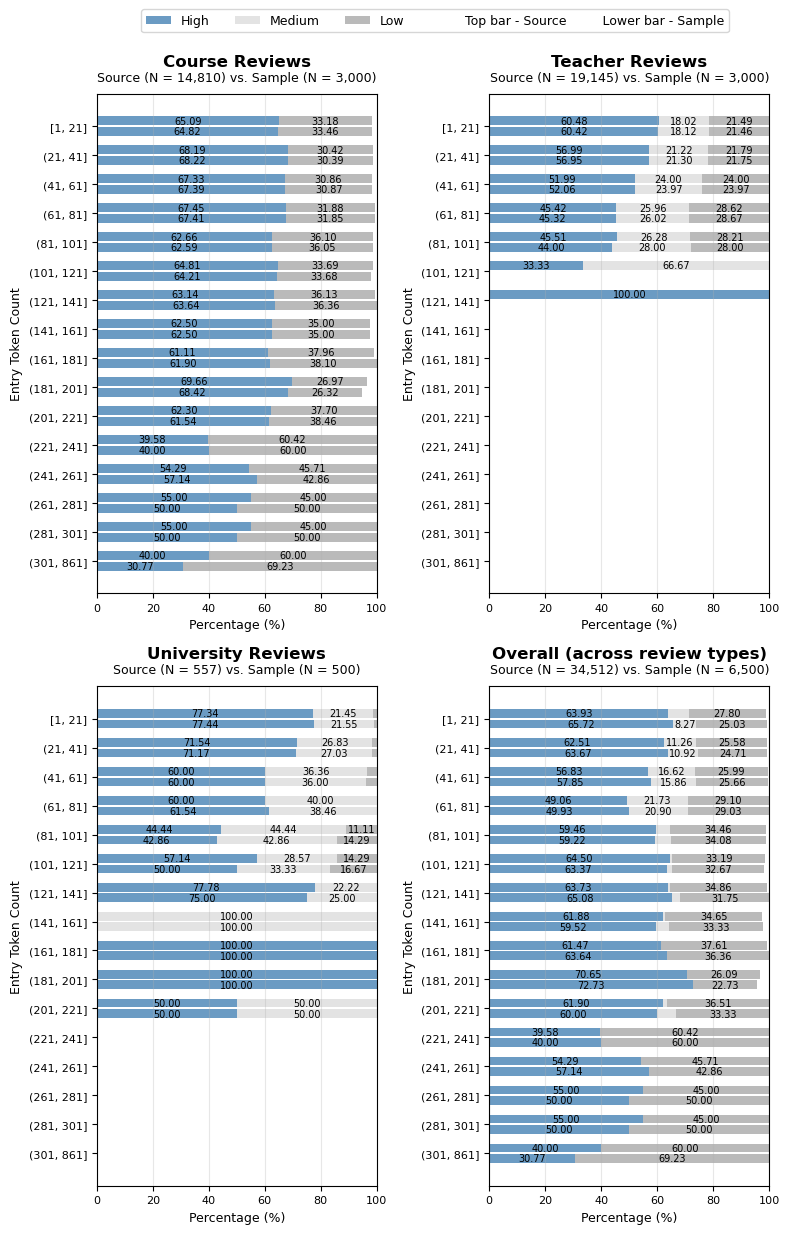

In [24]:
# FIGURE 4: Stacked Bar Chart - rating_cat Distribution by Token Length
fig4_path = os.path.join(output_file_dir, 'Fig4 - length by rating_cat percentage bargraph.png')

fig4, axes = plt.subplots(2, 2, figsize=(8, 12))

rating_cat_colors = ['steelblue', 'Gainsboro', 'darkgray']  # Green, Blue, Red

for i, plot_type in enumerate(plot_order):
    row, col = i // 2, i % 2
    ax = axes[row, col]
    
    y = np.arange(len(token_bins)) * 1.5
    height = 0.45  # Reduce from 0.8 to make bars thinner
    gap = 0.45     # Increase from 0.1 to create visible separation
    
    y_source = y - height/2 - gap/2
    y_sample = y + height/2 + gap/2
        
    # if plot_type == 'overall': 
    #     # If using mean of review types and normalize to 100%
    #     high_pct_source = np.mean([rating_cat_token_data[rt]['source']['High'] for rt in review_types], axis=0)
    #     med_pct_source = np.mean([rating_cat_token_data[rt]['source']['Medium'] for rt in review_types], axis=0)
    #     low_pct_source = np.mean([rating_cat_token_data[rt]['source']['Low'] for rt in review_types], axis=0)
    #     
    #     # Normalize source data to sum to 100% for each bin
    #     total_source = high_pct_source + med_pct_source + low_pct_source
    #     high_pct_source = np.where(total_source > 0, high_pct_source / total_source * 100, 0)
    #     med_pct_source = np.where(total_source > 0, med_pct_source / total_source * 100, 0)
    #     low_pct_source = np.where(total_source > 0, low_pct_source / total_source * 100, 0)
    # 
    #     high_pct_sample = np.mean([rating_cat_token_data[rt]['sample']['High'] for rt in review_types], axis=0)
    #     med_pct_sample = np.mean([rating_cat_token_data[rt]['sample']['Medium'] for rt in review_types], axis=0)
    #     low_pct_sample = np.mean([rating_cat_token_data[rt]['sample']['Low'] for rt in review_types], axis=0)
    #     
    #     # Normalize sample data to sum to 100% for each bin
    #     total_sample = high_pct_sample + med_pct_sample + low_pct_sample
    #     high_pct_sample = np.where(total_sample > 0, high_pct_sample / total_sample * 100, 0)
    #     med_pct_sample = np.where(total_sample > 0, med_pct_sample / total_sample * 100, 0)
    #     low_pct_sample = np.where(total_sample > 0, low_pct_sample / total_sample * 100, 0)
    
    if plot_type == 'overall':
        # If using pre-calculated overall data (true counts regardless of review type)
        high_pct_source = np.array(rating_cat_token_data['overall']['source']['High'])
        med_pct_source = np.array(rating_cat_token_data['overall']['source']['Medium'])
        low_pct_source = np.array(rating_cat_token_data['overall']['source']['Low'])

        high_pct_sample = np.array(rating_cat_token_data['overall']['sample']['High'])
        med_pct_sample = np.array(rating_cat_token_data['overall']['sample']['Medium'])
        low_pct_sample = np.array(rating_cat_token_data['overall']['sample']['Low'])
    else:
        # Individual review type
        high_pct_source = np.array(rating_cat_token_data[plot_type]['source']['High'])
        med_pct_source = np.array(rating_cat_token_data[plot_type]['source']['Medium'])
        low_pct_source = np.array(rating_cat_token_data[plot_type]['source']['Low'])
        
        high_pct_sample = np.array(rating_cat_token_data[plot_type]['sample']['High'])
        med_pct_sample = np.array(rating_cat_token_data[plot_type]['sample']['Medium'])
        low_pct_sample = np.array(rating_cat_token_data[plot_type]['sample']['Low'])
    
    # Create side-by-side stacked bars
    gap = 0.1
    y_source = y - height/2 - gap/2
    y_sample = y + height/2 + gap/2
    
    # Source bars (left)
    bars1_src = ax.barh(y_source, high_pct_source, height, label='High', color=rating_cat_colors[0], alpha=0.8)
    bars2_src = ax.barh(y_source, med_pct_source, height, left=high_pct_source, label='Medium', color=rating_cat_colors[1], alpha=0.8)
    bars3_src = ax.barh(y_source, low_pct_source, height, left=high_pct_source+med_pct_source, label='Low', color=rating_cat_colors[2], alpha=0.8)
    
    # Sample bars (right)
    bars1_smp = ax.barh(y_sample, high_pct_sample, height, color=rating_cat_colors[0], alpha=0.8)
    bars2_smp = ax.barh(y_sample, med_pct_sample, height, left=high_pct_sample, color=rating_cat_colors[1], alpha=0.8)
    bars3_smp = ax.barh(y_sample, low_pct_sample, height, left=high_pct_sample+med_pct_sample, color=rating_cat_colors[2], alpha=0.8)
    
    # Add percentage labels on bars (only for segments >8% to avoid clutter)
    for j in range(len(token_bins)):
        # Source bar labels
        if high_pct_source[j] > 8:
            ax.text(high_pct_source[j]/2, y_source[j], f'{high_pct_source[j]:.2f}', ha='center', va='center', 
                   color='black', fontweight='normal', fontsize=7)
        if med_pct_source[j] > 8:
            ax.text(high_pct_source[j] + med_pct_source[j]/2, y_source[j], f'{med_pct_source[j]:.2f}', ha='center', va='center', 
                   color='black', fontweight='normal', fontsize=7)
        if low_pct_source[j] > 8:
            ax.text(high_pct_source[j] + med_pct_source[j] + low_pct_source[j]/2, y_source[j], f'{low_pct_source[j]:.2f}', ha='center', va='center', 
                   color='black', fontweight='normal', fontsize=7)
        
        # Sample bar labels
        if high_pct_sample[j] > 8:
            ax.text(high_pct_sample[j]/2, y_sample[j], f'{high_pct_sample[j]:.2f}', ha='center', va='center', 
                   color='black', fontweight='normal', fontsize=7)
        if med_pct_sample[j] > 8:
            ax.text(high_pct_sample[j] + med_pct_sample[j]/2, y_sample[j], f'{med_pct_sample[j]:.2f}', ha='center', va='center', 
                   color='black', fontweight='normal', fontsize=7)
        if low_pct_sample[j] > 8:
            ax.text(high_pct_sample[j] + med_pct_sample[j] + low_pct_sample[j]/2, y_sample[j], f'{low_pct_sample[j]:.2f}', ha='center', va='center', 
                   color='black', fontweight='normal', fontsize=7)
    
    ax.set_title(titles[i], fontweight='bold', pad=20) # pad = 8 if without subheading
    
    # Add subheading with sample sizes
    subtitle = f"Source (N = {sample_sizes[plot_type]['source']:,}) vs. Sample (N = {sample_sizes[plot_type]['sample']:,})"
    ax.text(0.5, 1.02, subtitle, transform=ax.transAxes, ha='center', va='bottom', fontsize=9)
    
    ax.tick_params(axis='both', labelsize=8)  # Reduce tick label font size
    
    ax.set_xlim(0, 100)
    ax.set_xlabel('Percentage (%)', fontsize=9)
    
    if i in range(len(plot_order)):
        ax.set_ylabel('Entry Token Count', fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels(token_bins, fontsize=8)
    ax.invert_yaxis()
    
    ax.grid(True, alpha=0.3, axis='x')

# # Add shared legend centered horizontally
handles, labels = axes[0,0].get_legend_handles_labels() # Get handles from first subplot
# fig4.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.55, 1.03))

# Add source/sample distinction to legend
from matplotlib.patches import Patch
source_sampel_label = 'Top bar - Source         Lower bar - Sample'
source_sample_patch = Patch(facecolor='white', alpha=1, label=source_sampel_label)

# Combine rating_cat and data type legends
all_handles = handles + [source_sample_patch]
all_labels = labels + [source_sampel_label]
fig4.legend(all_handles, all_labels, loc='upper center', ncol=4, bbox_to_anchor=(0.55, 1.03), fontsize=9)

plt.subplots_adjust(top=0.93)  # Add space at top for legend

plt.tight_layout()
plt.savefig(fig4_path, bbox_inches='tight', dpi=1080)
print(f"\033[33mFig 4 saved to {fig4_path}\033[0m\n")

plt.show()

In [25]:
# Convert nested dict to long-format DataFrame
tempdict = {'source':[], 'sample':[]}

for review_type, review_data in rating_cat_token_data.items():
    for data_type, data_dict in review_data.items():  # source/sample
        for rating_cat, percentages in data_dict.items():
            for i, percentage in enumerate(percentages):
                row_content = {
                    'review_type': review_type,
                    'data_type': data_type, 
                    'rating_cat': rating_cat,
                    'token_bin': token_bins[i],
                    'percentage': percentage
                }
                tempdict['source'].append(row_content) if data_type == 'source' else tempdict['sample'].append(row_content)

source_datadf = pd.DataFrame(tempdict['source'])
sample_datadf = pd.DataFrame(tempdict['sample'])

source_datadf

,review_type,data_type,rating_cat,token_bin,percentage
0,course,source,High,"[1, 21]",65.093978
1,course,source,High,"(21, 41]",68.194622
2,course,source,High,"(41, 61]",67.328918
3,course,source,High,"(61, 81]",67.445365
4,course,source,High,"(81, 101]",62.655602
...,...,...,...,...,...
187,overall,source,Low,"(221, 241]",60.416667
188,overall,source,Low,"(241, 261]",45.714286
189,overall,source,Low,"(261, 281]",45.000000
190,overall,source,Low,"(281, 301]",45.000000


In [26]:
sample_datadf

,review_type,data_type,rating_cat,token_bin,percentage
0,course,sample,High,"[1, 21]",64.823642
1,course,sample,High,"(21, 41]",68.221942
2,course,sample,High,"(41, 61]",67.391304
3,course,sample,High,"(61, 81]",67.407407
4,course,sample,High,"(81, 101]",62.585034
...,...,...,...,...,...
187,overall,sample,Low,"(221, 241]",60.000000
188,overall,sample,Low,"(241, 261]",42.857143
189,overall,sample,Low,"(261, 281]",50.000000
190,overall,sample,Low,"(281, 301]",50.000000


In [27]:

# Print summary statistics
print("STRATIFIED SAMPLING VALIDATION SUMMARY")
print("=" * 50)

for review_type in review_types:
    print(f"\n{review_type.upper()} REVIEWS:")
    
    # Token length KS test simulation
    token_diff = np.mean(np.abs(np.array(token_data[review_type]['source']) - 
                                np.array(token_data[review_type]['sample'])))
    print(f"  Token length mean absolute difference: {token_diff:.2f}%")
    
    # rating_cat difference
    sent_diff = np.mean(np.abs(np.array(rating_cat_data[review_type]['source']) - 
                              np.array(rating_cat_data[review_type]['sample'])))
    print(f"  rating_cat mean absolute difference: {sent_diff:.2f}%")

is_good = token_diff < 1.0 and sent_diff < 1.0
color = '\033[32m' if is_good else '033[35m'
print(f"\nSampling appears {color}{'GOOD' if is_good else 'NEEDS REVIEW'}\033[0m")
print("Mean absolute difference < 1.0% indicates good stratification preservation.")

STRATIFIED SAMPLING VALIDATION SUMMARY

COURSE REVIEWS:
  Token length mean absolute difference: 0.04%
  rating_cat mean absolute difference: 0.10%

TEACHER REVIEWS:
  Token length mean absolute difference: 0.01%
  rating_cat mean absolute difference: 0.03%

UNIVERSITY REVIEWS:
  Token length mean absolute difference: 0.05%
  rating_cat mean absolute difference: 0.06%

Sampling appears GOOD
Mean absolute difference < 1.0% indicates good stratification preservation.
